# SVHN 이미지 다중분류 실습문제

실제 거리 사진에서 숫자 이미지를 입력받아 0부터 9까지 10개의 숫자 중 하나로 분류하는 CNN(합성곱 신경망)을 구현하시오.

- 데이터셋: SVHN (Street View House Numbers)
- 학습 데이터: 73,257개
- 테스트 데이터: 26,032개
- 추가 데이터: 531,131개 (이번 실습에서는 사용하지 않음)
- 이미지 크기: 32 × 32


| 구분 | 내용 |
|---|---|
| 데이터 | SVHN |
| 입력 데이터 | RGB 이미지 |
| 입력 Shape | `(3, 32, 32)` |
| 출력 데이터 | 10개 클래스 |
| 정답 레이블 | 0~9 |
| 손실함수 | `CrossEntropyLoss` |
| Optimizer | Adam |

In [2]:
# function 파일 오류 수정 후 런타임을 재시작하지 않고 수정내용을 반영하는 방법
# import importlib
# import multiclass_functions
# importlib.reload(multiclass_functions)

from multiclass_functions import *

In [3]:
import torch
from torch import nn, optim
from torch.utils.data import DataLoader, TensorDataset
from torchvision import transforms, datasets
import matplotlib.pyplot as plt
import numpy as np
import os
device = 'cuda' if torch.cuda.is_available() else 'cpu'

#### STEP 1. 라이브러리 불러오기 및 실행 환경 확인

**실습 조건**

| 변수 | 값 |
|---|---:|
| `BATCH_SIZE` | 64 |
| `EPOCH` | 10 |
| `LR` | 0.001 |
| `IMAGE_SIZE` | 32 |

In [ ]:
BATCH_SIZE = 64
LR = 1e-3
EPOCH = 10
criterion = nn.CrossEntropyLoss()
IMAGE_SIZE = 32

criterion = nn.CrossEntropyLoss()
new_model_train = True

model_type = 'CNN'
dataset = 'CIFAR10'

save_dir = 'results'
os.makedirs(save_dir, exist_ok=True)

save_model_path = f'{save_dir}/{model_type}_{dataset}.pt'

#### STEP 2. 데이터 다운로드 및 데이터셋 확인

**문제**

1. `torchvision.datasets.SVHN`을 이용하여 학습 데이터를 다운로드하시오.
2. 테스트 데이터를 다운로드하시오.
3. `split="train"`과 `split="test"`를 구분하여 사용하시오.
4. 학습 데이터와 테스트 데이터의 개수를 출력하시오.
5. 이미지와 정답 레이블의 구조를 확인하시오.

**주의** SVHN 데이터셋에서는 숫자 0의 레이블이 10으로 저장되어 있다. 모델에서 사용할 클래스 번호 0~9에 맞도록 변환하여 사용

#### STEP 3. 이미지 전처리 및 DataLoader 생성

**전처리 조건**

- `transforms.Compose()`를 이용하여 이미지 전처리를 구성한다.
- `transforms.ToTensor()`를 적용한다.
- 이미지 픽셀 값은 0~1 범위로 변환한다.( Scaling )
- 이미지 크기는 32 × 32를 유지한다.
- 학습 데이터와 테스트 데이터에 동일한 전처리를 적용한다.
- 학습 데이터 중 20%를 검증 데이터로 분리한다.

**문제**

1. 이미지 전처리를 구성하시오.
2. 학습 데이터와 테스트 데이터에 전처리를 적용하시오.
3. SVHN의 정답 레이블 10을 0으로 변환하시오.
4. 학습 데이터의 20%를 검증 데이터로 분리하시오.
5. 학습·검증·테스트용 `DataLoader`를 생성하시오.
6. 학습 데이터는 `shuffle=True`, 검증 및 테스트 데이터는 `shuffle=False`로 설정하시오.
7. 첫 번째 배치의 이미지와 정답 레이블 shape를 출력하시오.
8. 이미지 9장을 정답 레이블과 함께 시각화하시오.

**주의:** SVHN 데이터셋에는 `classes` 속성이 기본 제공되지 않는다. 숫자 클래스 이름 목록을 준비하여 시각화 및 혼동행렬에 활용하시오.

In [51]:
# 이미지 전처리 구정
# transform = transforms.Compose([
#     transforms.ToTensor()
# ])
transform = transforms.ToTensor()

train_DS = datasets.SVHN(root='data', split='train', download=True, transform=transform)
test_DS = datasets.SVHN(root='data', split='test', download=True, transform=transform)

In [52]:
# 정답 레이블명 변경
train_DS.classes=[str(i)for i in range(10)]
test_DS.classes=[str(i) for i in range(10)]

In [70]:
x, y = train_DS[0]

print('Train size :', len(train_DS))
print('Test size  :', len(test_DS))
print('Image shape:', x.shape)
print('Image dtype:', x.dtype)
print('Label      :', y)
print('n_class    :', len(train_DS.classes))

Train size : 73257
Test size  : 26032
Image shape: torch.Size([3, 32, 32])
Image dtype: torch.float32
Label      : 1
n_class    : 10


In [65]:
split_idx = int(len(train_DS) * 0.8)

x_train = train_DS.data[:split_idx]
x_val = train_DS.data[split_idx:]

y_train = train_DS.labels[:split_idx]
y_val = train_DS.labels[split_idx:]

In [59]:
x_train_ts = torch.tensor(x_train, dtype=torch.float32) / 255.
x_val_ts = torch.tensor(x_val, dtype=torch.float32) / 255.

y_train_ts = torch.tensor(y_train, dtype=torch.long)
y_val_ts = torch.tensor(y_val, dtype=torch.long)

train_subset = TensorDataset(x_train_ts, y_train_ts)
val_subset = TensorDataset(x_val_ts, y_val_ts)

In [60]:
train_DL = DataLoader(
    train_subset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_DL = DataLoader(
    val_subset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_DL = DataLoader(
    test_DS,
    batch_size=BATCH_SIZE,
    shuffle=False
)

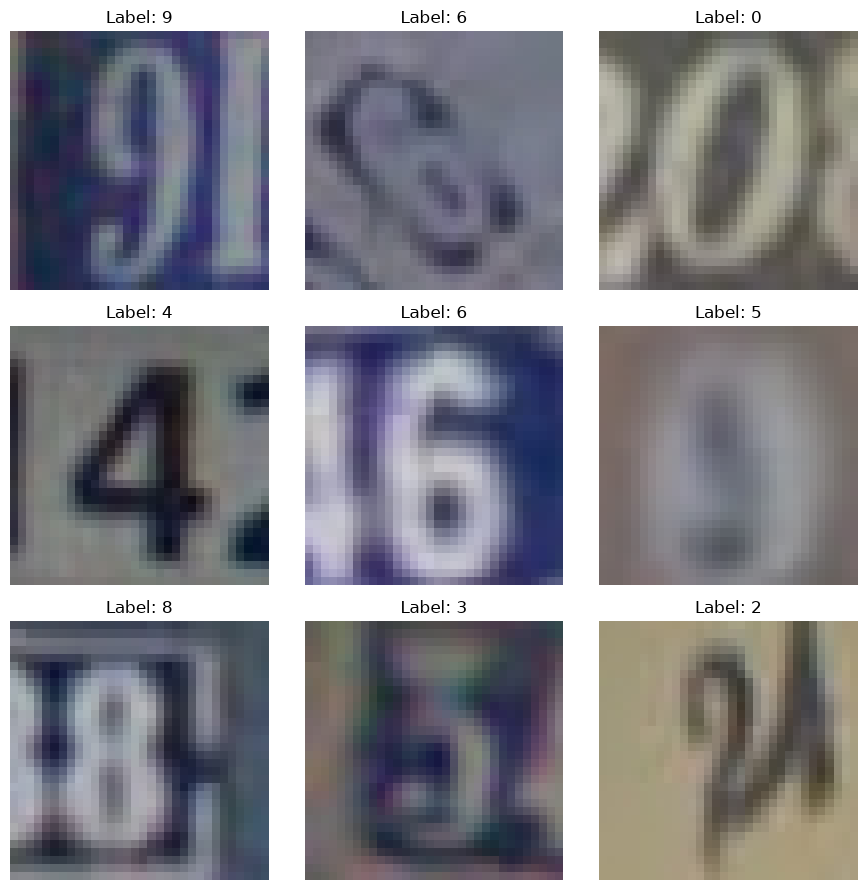

In [63]:
x_batch, y_batch = next(iter(train_DL))

plt.figure(figsize=(9, 9))

for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(x_batch[i].permute(1, 2, 0))
    plt.title(f'Label: {y_batch[i].item()}')
    plt.axis('off')

plt.tight_layout()
plt.show()

#### STEP 4. CNN 모델 만들기

**목표:** 이미지에서 숫자의 특징을 추출하는 CNN 모델을 구성한다.

**모델 조건**

- 입력: 3채널 RGB 이미지, 크기 32×32
- 첫 번째 합성곱 층: 3 → 32 채널, 커널 3×3, padding=1
- 두 번째 합성곱 층: 32 → 64 채널, 커널 3×3, padding=1
- 세 번째 합성곱 층: 64 → 128 채널, 커널 3×3, padding=1
- 각 합성곱 층 뒤에 ReLU와 2×2 MaxPool을 적용한다.
- `AdaptiveAvgPool2d((1, 1))`로 특징맵 크기를 1×1로 맞춘다.
- Flatten 후 완전연결(fullconnect)층을 적용한다.
- 출력층: `Linear(128, 10)`

**문제**

1. `nn.Module`을 상속받아 CNN 클래스를 정의하시오.
2. `forward()` 함수를 구현하시오.
3. 모델을 생성하고 `DEVICE`로 이동하시오.
4. 모델 구조를 출력하시오.
5. 임의의 입력 5장으로 출력 shape를 확인하시오. 결과는 `(5, 10)`이어야 한다.

In [80]:
class CNN(nn.Module):
    def __init__(self,*args, **kwargs):
        super().__init__(*args, **kwargs)
        self.conv1 = nn.Sequential(nn.Conv2d(3,32,3,padding=1),
                                   nn.BatchNorm2d(32),
                                   nn.ReLU(),
                                   )
        self.maxpool1 = nn.MaxPool2d(2)
        self.conv2 = nn.Sequential(nn.Conv2d(32,64,3,padding=1),
                                   nn.BatchNorm2d(64),
                                   nn.ReLU(),
                                   )
        self.maxpool2 = nn.MaxPool2d(2)
        self.conv3 = nn.Sequential(nn.Conv2d(64,128,3,padding=1),
                                   nn.BatchNorm2d(128),
                                   nn.ReLU(),
                                   )
        self.maxpool3 = nn.MaxPool2d(2)
        self.adaptpool = nn.AdaptiveAvgPool2d((1,1))
        self.fc = nn.Linear(128,10)

    def forward(self, x, *args, **kwargs):
        x = self.conv1(x)
        x = self.maxpool1(x)
        x = self.conv2(x)
        x = self.maxpool2(x)
        x = self.conv3(x)
        x = self.maxpool3(x)
        x = self.adaptpool(x)
        x = torch.flatten(x, start_dim=1)
        x = self.fc(x)
        return x

In [81]:
model = globals()[model_type]().to(device)

# 모델 구조 출력
model.eval()

x_batch, y_batch = next(iter(train_DL))
x_batch = x_batch.to(DEVICE)

with torch.no_grad():
    conv1 = model.conv1(x_batch)
    conv2 = model.conv2(model.maxpool1(conv1))
    conv3 = model.conv3(model.maxpool2(conv2))
    flat = torch.flatten(model.adaptpool(model.maxpool3(conv3)), start_dim=1)
    fc = model.fc(flat)

print('Input   :', x_batch.shape)
print('Conv1   :', conv1.shape)
print('Conv2   :', conv2.shape)
print('Conv3   :', conv3.shape)
print('Flatten :', flat.shape)
print('Output  :', fc.shape)

Input   : torch.Size([64, 3, 32, 32])
Conv1   : torch.Size([64, 32, 32, 32])
Conv2   : torch.Size([64, 64, 16, 16])
Conv3   : torch.Size([64, 128, 8, 8])
Flatten : torch.Size([64, 128])
Output  : torch.Size([64, 10])


#### STEP 5. 모델 학습시키기

**학습 조건**

- Loss function: `nn.CrossEntropyLoss()`
- Optimizer: `optim.Adam()`
- Learning Rate: `0.001`
- Epoch: 10
- Batch size: 64

**문제**

1. 손실함수를 정의하시오.
2. Optimizer를 정의하시오.
3. `multiclass_functions.py`의 `Train()` 함수를 이용하여 모델을 학습시키시오.
4. Epoch별 평균 Train Loss를 기록하시오.
5. 학습 Loss 그래프를 시각화하시오.

In [90]:
def train(dataloader, model, loss_fn, optimizer, device):
    num_batches = len(train_DL.dataset)

    for x_train_ts, y_train_ts in dataloader:
        x, y = x_train_ts.to(device), y_train_ts.to(device)

        pred = model(x)
        loss = loss_fn(pred, y)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        loss_b = loss.item() * x.shape[0]
        rloss += loss_b
    loss_e = rloss/ num_batches
    return loss_e

In [91]:
def evaluate(dataloader, model, loss_fn, device):
    model.eval()
    with torch.no_grad():
        for x, y in dataloader:
            x, y = x_val_ts.to(device), y_val_ts.to(device)
            pred = model(x)
            val_loss = loss_fn(pred, y).item()
    return val_loss, pred

In [92]:
def learning_curve(tr_loss_list, val_loss_list):
    epochs = list(range(1, len(tr_loss_list)+1))
    plt.plot(epochs, tr_loss_list, label='train error', marker='.')
    plt.plot(epochs, val_loss_list, label='val error', marker='.')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.grid(True)
    plt.legend()
    plt.show()

Epoch : 1, train loss : 1.532
--------------------
Epoch : 2, train loss : 0.802
--------------------
Epoch : 3, train loss : 0.577
--------------------
Epoch : 4, train loss : 0.481
--------------------
Epoch : 5, train loss : 0.425
--------------------
Epoch : 6, train loss : 0.384
--------------------
Epoch : 7, train loss : 0.357
--------------------
Epoch : 8, train loss : 0.328
--------------------
Epoch : 9, train loss : 0.307
--------------------
Epoch : 10, train loss : 0.293
--------------------


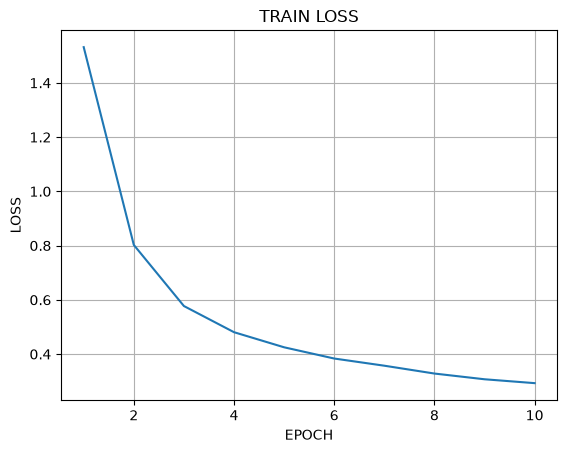

In [ ]:
optimizer = optim.Adam(model.parameters(), lr=LR)
tr_loss_list, val_loss_list = [], []
if new_model_train:
    for ep in range(EPOCH):
        tr_loss = train(train_DL, model, criterion, optimizer, device)
        val_loss = evaluate(val_DL, model, criterion, device)
        tr_loss_list.append(tr_loss)
        val_loss_list.append(val_loss)
        print(f'Ep {ep+1}, TL {tr_loss:.4f}, VL {val_loss:.4f}')

    torch.save(model, save_model_path)
    learning_curve(tr_loss_list, val_loss_list)


#### STEP 6. 모델 저장 및 불러오기

**문제**

1. 학습이 끝난 모델의 `state_dict()`를 `results` 폴더에 저장하시오.
2. 동일한 CNN 구조를 새로 생성하시오.
3. 저장한 가중치를 `torch.load(..., map_location=DEVICE)`로 불러오시오.
4. 새 모델에 `load_state_dict()`를 적용하시오.
5. 불러온 모델을 `DEVICE`로 이동하고 `eval()` 모드로 전환하시오.

저장 파일명 예시: `CNN_SVHN.pt`

In [83]:
load_model = torch.load(save_model_path, map_location= device, weights_only=False)

#### STEP 7. 모델 테스트하기

**문제**

1. 불러온 모델을 이용하여 테스트 데이터의 예측값을 계산하시오.
2. `torch.no_grad()`를 이용하여 추론하시오.
3. `argmax(dim=1)`로 예측 클래스를 구하시오.
4. `multiclass_functions.py`의 `Test()` 함수를 이용하여 테스트 정확도를 계산하시오.
5. 정답 개수와 전체 테스트 데이터 개수를 출력하시오.

In [84]:
Test(load_model, test_DL)
print(count_params(load_model))

Test accuracy : 23135 / 26032 (88.9 %)
94986


#### STEP 8. 테스트 결과 시각화

**문제**

1. 테스트 이미지 6장을 시각화하시오.
2. 각 이미지의 실제 정답과 예측 결과를 표시하시오.
3. 정답과 예측이 다르면 제목을 빨간색으로 표시하시오.

**주의:** SVHN은 기본적으로 `classes` 속성을 제공하지 않으므로 숫자 클래스 이름 목록을 사용하시오.

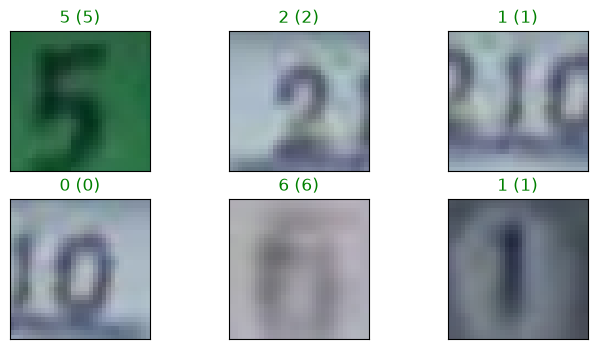

In [85]:
Test_plot(load_model, test_DL)

#### STEP 9. 혼동행렬 및 오분류 이미지 분석

**문제 1. Confusion Matrix**

1. `plot_confusion_matrix()` 함수를 이용하여 혼동행렬을 시각화하시오.
2. 행(Row)은 실제 클래스, 열(Column)은 예측 클래스로 표시하시오.
3. 숫자별 정답 개수와 오분류 개수를 확인하시오.

**문제 2. 오분류 이미지 확인**

1. 테스트 데이터에서 실제 정답과 예측값이 다른 인덱스를 찾으시오.
2. 오분류 이미지 중 최대 9장을 시각화하시오.
3. 이미지 위에 실제 정답과 예측값을 표시하시오.
4. 오분류 이미지가 없으면 '오분류 이미지가 없습니다'를 출력하시오.

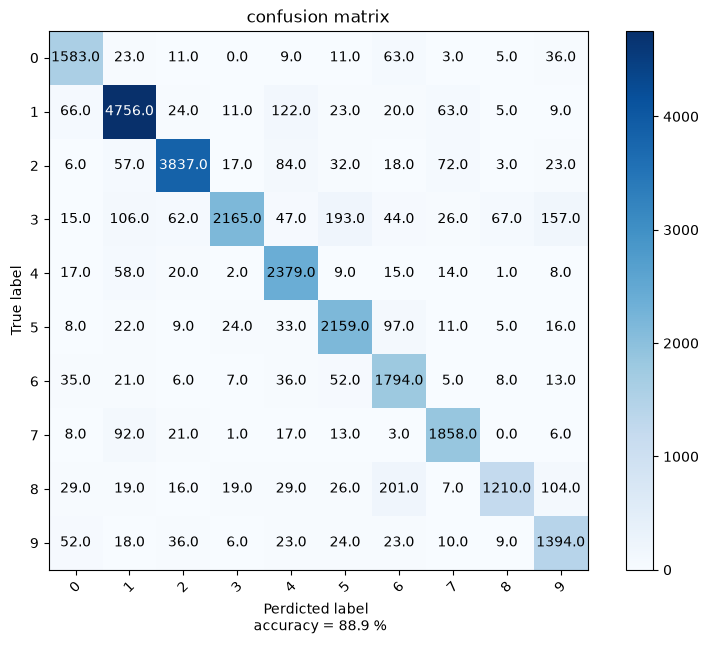

In [86]:
confusion = get_conf(load_model, test_DL)

plot_confusion_matrix(confusion, test_DS.classes)

plt.xticks(rotation=45);

#### STEP 10. 파라미터 개수 확인

**문제**

1. 학습 가능한 전체 파라미터 개수를 출력하시오.
2. Conv2d와 Linear 계층의 파라미터 개수를 각각 확인하시오.
3. CNN 모델의 학습 가능한 파라미터가 어느 계층에 많이 분포하는지 확인하시오.

In [87]:
total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print(f'Total parameters     : {total_params:,}')
print(f'Trainable parameters : {trainable_params:,}')

Total parameters     : 94,986
Trainable parameters : 94,986
